# Topic 21f - Composition and seaborn

The main lesson introduced pie and waffle charts as the narrow exception to the bar-chart default, and seaborn as a faster way to build charts you already know how to read. This notebook goes deeper on both: when a pie chart actively misleads, the waffle chart's print-friendly form, and seaborn's statistical plot types and theming.

Work through it after reading section 7 and 8 of the [main lesson](topic21_data_visualization.ipynb).

In [1]:
# Run this cell as it is.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker


def find_data_dir():
    """Locate the lesson's data folder from the repository root, the lesson
    folder, or the assignments folder, so this notebook runs from anywhere."""
    candidates = [
        Path.cwd() / "data",
        Path.cwd() / "data_visualization" / "data",
        Path.cwd().parent / "data",
    ]
    for candidate in candidates:
        if (candidate / "orders.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find orders.csv. Expected a data folder containing the six "
        "Topic 20/21 tables. Looked in: " + ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

# The course palette. Hues are assigned in this fixed order to every chart in
# Topic 21 - never cycled, never re-generated - so a category keeps the same
# colour in every chart it appears in. See 21a for why this matters.
PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"    # de-emphasis grey, for "everything but the finding"
INK = "#0b0b0b"      # text and value labels

# Fixed colour assignment per category, used throughout this topic.
ZONE_COLOR = {"Coastal": PALETTE["blue"], "Middle": PALETTE["aqua"], "Northern": PALETTE["yellow"]}
CHANNEL_COLOR = {"Field Agent": PALETTE["blue"], "Online": PALETTE["aqua"],
                 "Phone": PALETTE["yellow"], "Shop": PALETTE["green"]}
SEGMENT_COLOR = {"Retail": PALETTE["blue"], "Wholesale": PALETTE["aqua"], "Institution": PALETTE["yellow"]}
CATEGORY_COLOR = {
    "Beverages": PALETTE["blue"], "Grains": PALETTE["aqua"], "Cooking Oils": PALETTE["yellow"],
    "Personal Care": PALETTE["green"], "Household": PALETTE["violet"], "Snacks": PALETTE["red"],
    "Canned Goods": PALETTE["magenta"],
}

print("pandas version:   ", pd.__version__)
print("data folder:      ", DATA_DIR)
print("files:            ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

pandas version:    3.0.6
data folder:       /home/johnny/Projects/itfy-da/data_visualization/data
files:             ['customers.csv', 'monthly_targets_wide.csv', 'orders.csv', 'products.csv', 'regions.csv', 'returns.csv']


In [2]:
# Paste the function you built in Topic 20. This is the same contract: five
# raw tables in, one analysis-ready table out, with its own row-count check.
def clean_region(series):
    return (series.str.strip()
                  .str.replace(r"\s+", " ", regex=True)
                  .str.title())


def build_analysis_table(orders, customers, products, regions, returns):
    """Combine the five raw tables into one analysis-ready table (Topic 20)."""
    expected_rows = len(orders)

    customers = customers.copy()
    customers["region"] = clean_region(customers["region"])
    products = products.drop_duplicates(subset="product_id", keep="first")
    customers = customers.merge(regions, on="region", how="left", validate="m:1")

    table = (orders
             .merge(customers, on="customer_id", how="left", validate="m:1")
             .merge(products, on="product_id", how="left", validate="m:1"))

    returned_ids = set(returns["order_id"])
    table["was_returned"] = table["order_id"].isin(returned_ids)

    table["order_date"] = pd.to_datetime(table["order_date"])
    table["month"] = table["order_date"].dt.strftime("%b")
    table["weekday"] = table["order_date"].dt.day_name()
    table["revenue_ghs"] = (table["quantity"] * table["unit_price_ghs"]).round(2)
    table["cost_ghs"] = (table["quantity"] * table["unit_cost_ghs"]).round(2)
    table["profit_ghs"] = (table["revenue_ghs"] - table["cost_ghs"]).round(2)

    if len(table) != expected_rows:
        raise ValueError(
            f"Row count changed during wrangling: {expected_rows} -> {len(table)}. "
            "A merge has duplicated rows."
        )
    return table.sort_values("order_date").reset_index(drop=True)


orders = pd.read_csv(DATA_DIR / "orders.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
regions = pd.read_csv(DATA_DIR / "regions.csv")
returns = pd.read_csv(DATA_DIR / "returns.csv")
targets_wide = pd.read_csv(DATA_DIR / "monthly_targets_wide.csv")

analysis = build_analysis_table(orders, customers, products, regions, returns)
print(f"Analysis table: {analysis.shape[0]} rows x {analysis.shape[1]} columns")
print(f"Total revenue: GHS {analysis['revenue_ghs'].sum():,.2f}")
print(f"Total profit:  GHS {analysis['profit_ghs'].sum():,.2f}")

Analysis table: 1200 rows x 24 columns
Total revenue: GHS 230,001.08
Total profit:  GHS 65,886.38


---

## When a pie chart actively misleads

The channel-mix pie in the main lesson was a defensible case: four slices, genuinely summing to a whole, with visibly different sizes. Here is the failure case - seven product categories, several of them close in size - built the same way.

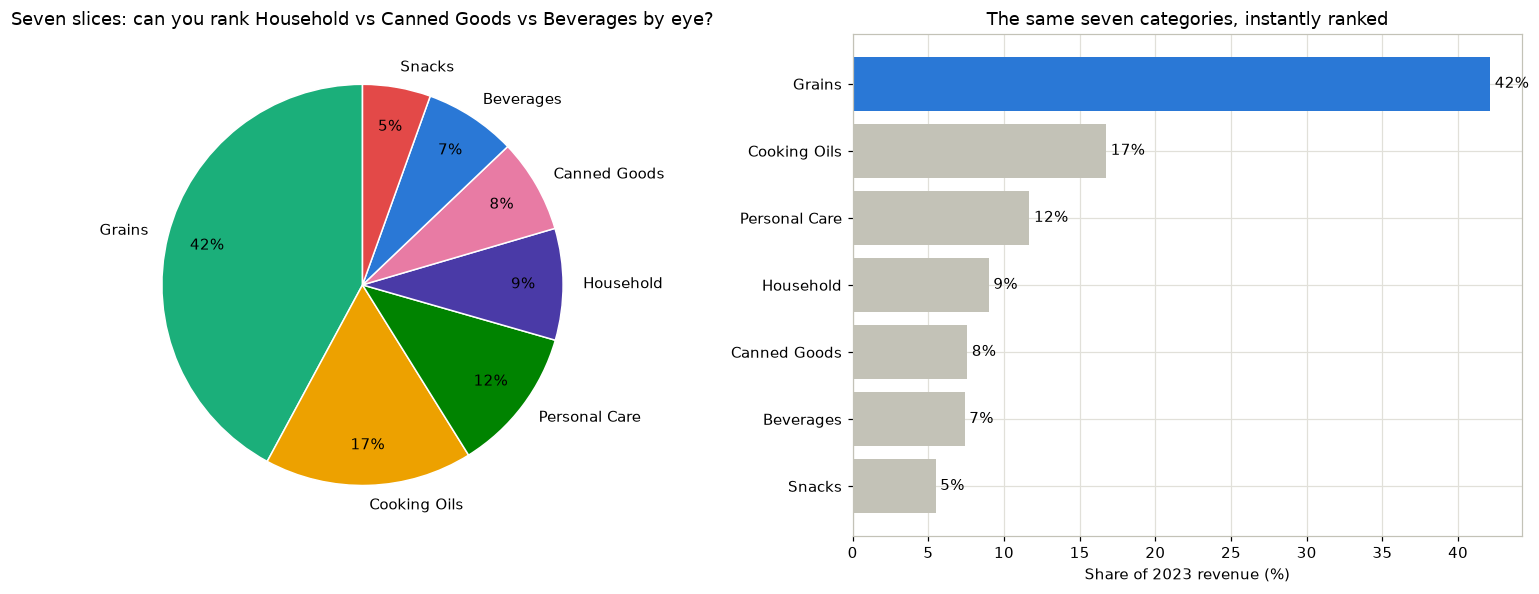

category
Grains           42.1
Cooking Oils     16.7
Personal Care    11.7
Household         9.0
Canned Goods      7.6
Beverages         7.4
Snacks            5.5


In [3]:
category_share = (analysis.groupby("category")["revenue_ghs"].sum()
                   .pipe(lambda s: s / s.sum() * 100).sort_values(ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].pie(category_share.values, labels=category_share.index, autopct="%1.0f%%",
            startangle=90, pctdistance=0.8,
            colors=[CATEGORY_COLOR[c] for c in category_share.index],
            wedgeprops={"edgecolor": "white", "linewidth": 1})
axes[0].set_title("Seven slices: can you rank Household vs Canned Goods vs Beverages by eye?")

bars = axes[1].barh(category_share.index[::-1], category_share.values[::-1],
                     color=[PALETTE["blue"] if c == category_share.index[0] else MUTED
                            for c in category_share.index[::-1]])
axes[1].bar_label(bars, fmt="%.0f%%", padding=3)
axes[1].set_title("The same seven categories, instantly ranked")
axes[1].set_xlabel("Share of 2023 revenue (%)")

fig.tight_layout()
plt.show()

print(category_share.round(1).to_string())

Household (9.0%), Canned Goods (7.6%), and Beverages (7.4%) are close enough in the pie that ranking them by slice angle alone is close to guessing. The bar chart ranks all seven correctly without the reader doing any work. This is the concrete version of the "≤5 categories" gate the main lesson stated - it is not an arbitrary number, it is the point past which slice angles stop being distinguishable at a glance.

---

## The waffle chart, and its one real advantage

A waffle chart trades the pie's one visual advantage (a single, instantly-recognised "whole") for a grid that is easier to read precisely - counting squares is more accurate than judging an angle - and, built with hatch patterns instead of fill colour, it is the one composition chart in this lesson that survives being printed in black and white or viewed by a reader with colour-vision deficiency.

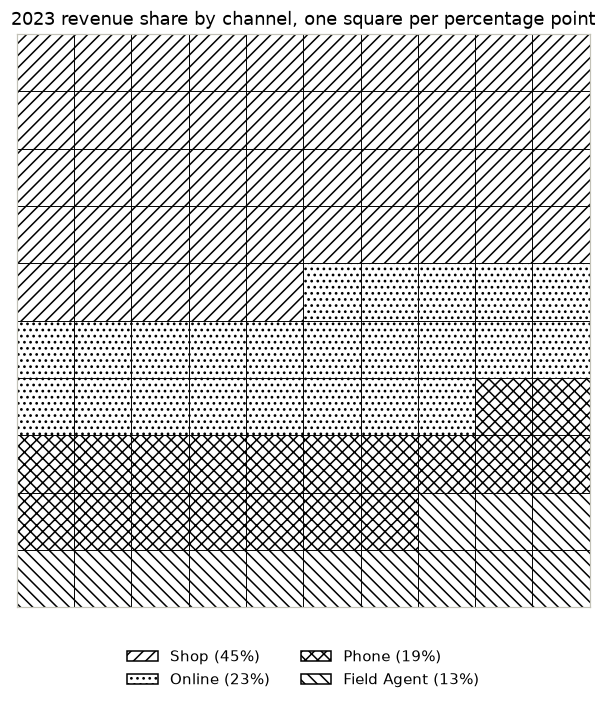

In [4]:
channel_share = (analysis.groupby("channel")["revenue_ghs"].sum()
                  .pipe(lambda s: (s / s.sum() * 100).round(0).astype(int))
                  .sort_values(ascending=False))
channel_share.iloc[0] += 100 - channel_share.sum()  # rounding to exactly 100 squares

hatches = ["///", "...", "xxx", "\\\\\\"]
fig, ax = plt.subplots(figsize=(6.5, 6.5))
rows, cols = 10, 10
square = 0
for (label, pct), hatch in zip(channel_share.items(), hatches):
    for _ in range(pct):
        r, c = divmod(square, cols)
        ax.add_patch(plt.Rectangle((c, rows - 1 - r), 1, 1, facecolor="white",
                                    edgecolor="black", hatch=hatch, linewidth=0.6))
        square += 1

handles = [plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor="black", hatch=h) for h in hatches]
ax.legend(handles, [f"{label} ({pct}%)" for label, pct in channel_share.items()],
          loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=2, frameon=False)
ax.set_xlim(0, cols)
ax.set_ylim(0, rows)
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("2023 revenue share by channel, one square per percentage point")
fig.tight_layout()
plt.show()

The rounding correction (`channel_share.iloc[0] += 100 - channel_share.sum()`) exists because rounding four percentages independently will not reliably sum to exactly 100 - without it, the grid comes up one square short or one square long, which is a worse failure for a waffle chart than it would be for almost any other chart type, because "100 squares" is the entire premise.

---

## Seaborn: theming and statistical plot types

`sns.set_theme()` changes matplotlib's global defaults - grid style, font scale, colour cycle - for every chart built afterwards in the same session. This course sets its own grid and spine style in every notebook's setup cell, so calling `sns.set_theme()` carelessly can silently undo it. Pass `rc=` to layer seaborn's theme on top of this course's choices instead of replacing them.

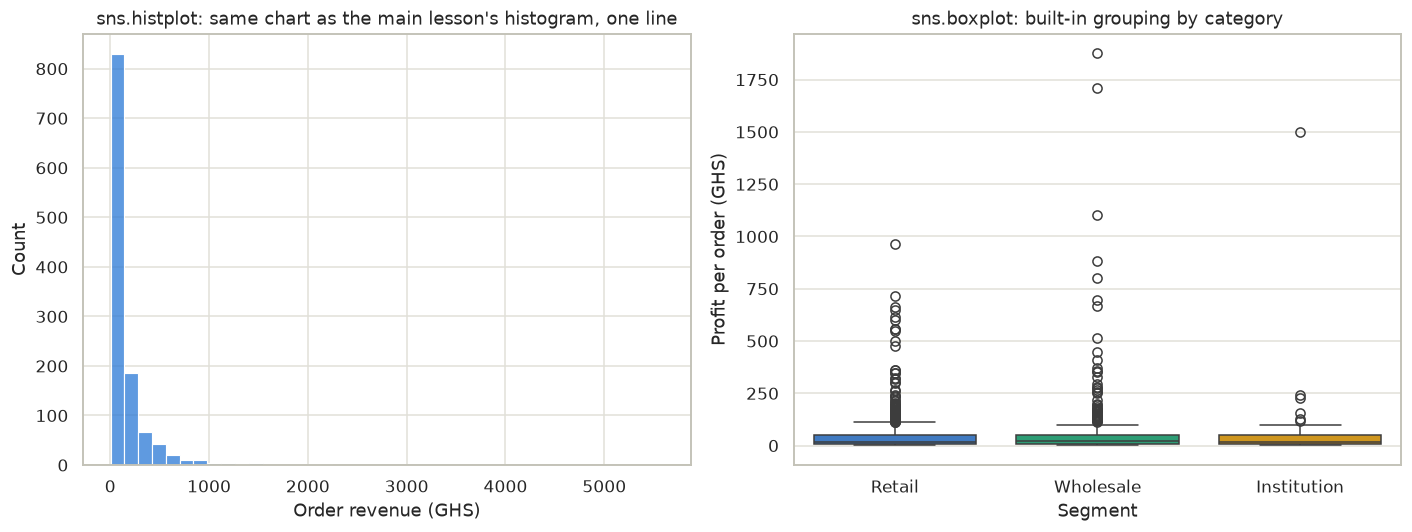

In [5]:
import seaborn as sns

sns.set_theme(style="white", rc={
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9", "axes.grid": True,
})
segment_order = ["Retail", "Wholesale", "Institution"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=analysis, x="revenue_ghs", bins=40, color=PALETTE["blue"], ax=axes[0])
axes[0].set_title("sns.histplot: same chart as the main lesson's histogram, one line")
axes[0].set_xlabel("Order revenue (GHS)")

sns.boxplot(data=analysis, x="segment", y="profit_ghs", order=segment_order,
            hue="segment", palette=SEGMENT_COLOR, legend=False, ax=axes[1])
axes[1].set_title("sns.boxplot: built-in grouping by category")
axes[1].set_xlabel("Segment")
axes[1].set_ylabel("Profit per order (GHS)")

fig.tight_layout()
plt.show()

`hue="segment", palette=SEGMENT_COLOR, legend=False` is the pattern for keeping this course's fixed colour assignment inside a seaborn call that would otherwise pick its own palette - `palette=` accepts the same dict you have been building bar and line charts from all topic. Seaborn saves the most code on exactly the plots that need grouping, a fitted statistic, or both - a plain single-series bar or line is often no shorter in seaborn than in matplotlib, which is why the main lesson still reaches for matplotlib directly most of the time.

### Try It 6 - a seaborn panel

Using seaborn, build a 1x2 figure: left panel `sns.scatterplot` of quantity vs revenue coloured by segment (use `hue="segment", palette=SEGMENT_COLOR`); right panel `sns.barplot` of average order value (`revenue_ghs`) by channel, coloured with `color=PALETTE["blue"]`. Give both panels a title that states a finding.

In [6]:
segment_order = ["Retail", "Wholesale", "Institution"]
# YOUR CODE HERE

---
## Where this fits

- [Back to the main lesson](topic21_data_visualization.ipynb)
- Previous: [21e - Relationships](topic21e_relationships.ipynb)
- Next: [21g - Visualization practice](topic21g_visualization_practice.ipynb)